# 03 Preprocessing and PCA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style='whitegrid')

In [2]:
df = pd.read_csv('../data/processed/countries_2019.csv')
names = ['GDP_PC', 'GDP_GROWTH', 'INFLATION', 'UNEMPLOYMENT', 'TRADE', 'CAPITAL_FORMATION',
         'LIFE_EXPECTANCY', 'URBAN_POP', 'INTERNET_USERS', 'ELECTRICITY_ACCESS', 'SECONDARY_ENROLLMENT']
income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']

def skewness(x):
    x = x.dropna()
    return ((x - x.mean()) ** 3).mean() / x.std() ** 3

## Transformations

In [3]:
features = df[names].copy()
features['GDP_PC'] = np.log(features['GDP_PC'])
features['TRADE'] = np.log(features['TRADE'])

for name in ['INFLATION', 'GDP_GROWTH']:
    low = features[name].quantile(0.05)
    high = features[name].quantile(0.95)
    x = features[name].copy()
    x[x < low] = low
    x[x > high] = high
    features[name] = x
    print(f'{name}: capped to [{low:.2f}, {high:.2f}]')

INFLATION: capped to [-0.67, 14.86]
GDP_GROWTH: capped to [-2.32, 6.94]


In [4]:
skew_table = pd.DataFrame()
for name in names:
    skew_table.loc[name, 'before'] = skewness(df[name])
    skew_table.loc[name, 'after'] = skewness(features[name])
skew_table.round(2)

,before,after
GDP_PC,1.97,-0.04
GDP_GROWTH,-1.74,-0.19
INFLATION,10.93,1.79
UNEMPLOYMENT,1.48,1.48
TRADE,2.43,0.38
CAPITAL_FORMATION,0.75,0.75
LIFE_EXPECTANCY,-0.96,-0.96
URBAN_POP,-0.20,-0.20
INTERNET_USERS,-0.44,-0.44
ELECTRICITY_ACCESS,-1.61,-1.61


## Median imputation and standardization

In [5]:
imputer = SimpleImputer(strategy='median')
features_imputed = imputer.fit_transform(features)

scaler = StandardScaler()
Z = scaler.fit_transform(features_imputed)
print(Z.shape)
print(Z.mean(axis=0).round(3))
print(Z.std(axis=0).round(3))

(186, 11)
[-0. -0. -0. -0. -0. -0.  0. -0.  0.  0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [6]:
standardized = pd.DataFrame(Z, columns=names)
standardized['country'] = df['country']
standardized['code'] = df['code']
standardized['income_group'] = df['income_group']
standardized['region'] = df['region']
standardized['complete'] = df['n_missing'] == 0
standardized.to_csv('../data/processed/standardized_2019.csv', index=False)

## Correlations of standardized features

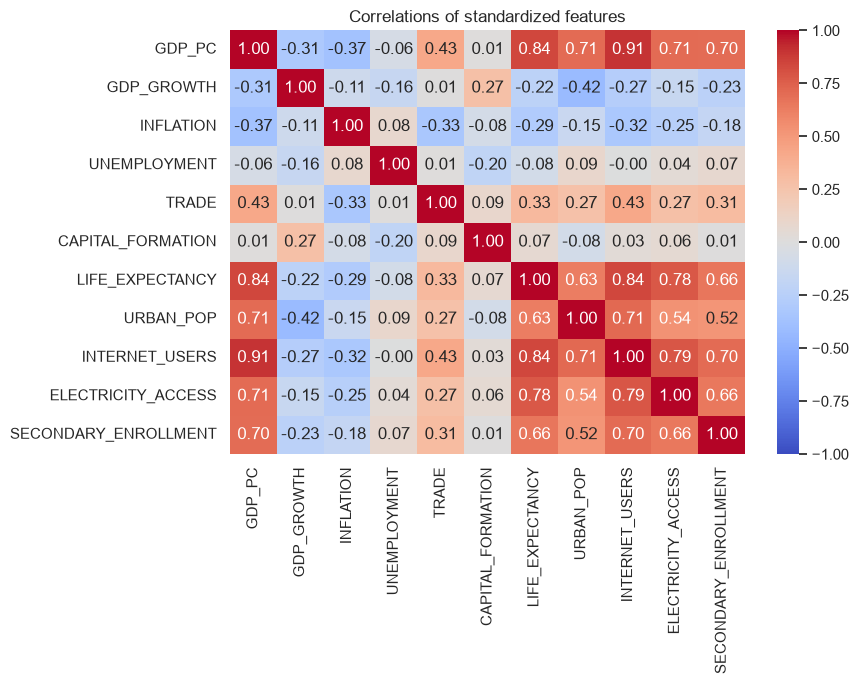

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(standardized[names].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlations of standardized features')
plt.tight_layout()
plt.savefig('../figures/03_correlation_standardized.png', dpi=200)
plt.show()

## PCA

In [8]:
pca = PCA()
pca.fit(Z)
evr = pca.explained_variance_ratio_
print('explained variance ratio:', evr.round(3))
print('cumulative:', np.cumsum(evr).round(3))
print('components for 90%:', np.argmax(np.cumsum(evr) >= 0.90) + 1)

explained variance ratio: [0.454 0.144 0.091 0.078 0.065 0.056 0.039 0.031 0.02  0.014 0.007]
cumulative: [0.454 0.598 0.69  0.768 0.833 0.889 0.928 0.959 0.979 0.993 1.   ]
components for 90%: 7


### Check with eigen-decomposition of the covariance matrix

In [9]:
cov_matrix = np.cov(Z, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
sort_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_indices]
print('eigenvalues:', eigenvalues.round(3))
print('EVR from eigenvalues:', (eigenvalues / eigenvalues.sum()).round(3))
print('same as sklearn:', np.allclose(eigenvalues / eigenvalues.sum(), evr))

eigenvalues: [5.021 1.597 1.009 0.868 0.716 0.618 0.432 0.343 0.221 0.156 0.078]
EVR from eigenvalues: [0.454 0.144 0.091 0.078 0.065 0.056 0.039 0.031 0.02  0.014 0.007]
same as sklearn: True


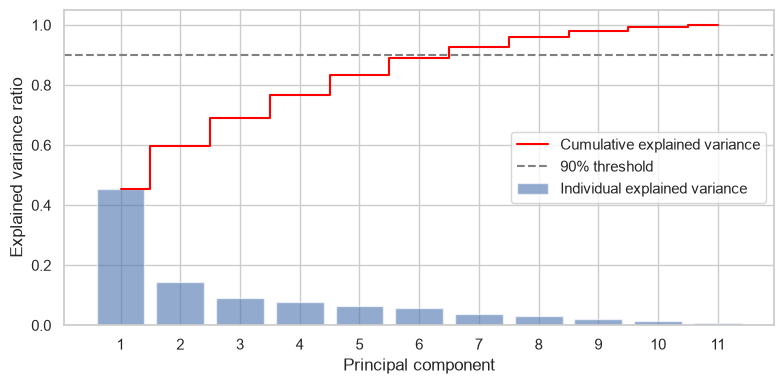

In [10]:
components = np.arange(1, 12)
plt.figure(figsize=(8, 4))
plt.bar(components, evr, alpha=0.6, label='Individual explained variance')
plt.step(components, np.cumsum(evr), where='mid', color='red', label='Cumulative explained variance')
plt.axhline(y=0.90, color='grey', linestyle='--', label='90% threshold')
plt.xticks(components)
plt.xlabel('Principal component')
plt.ylabel('Explained variance ratio')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/03_scree.png', dpi=200)
plt.show()

### Loadings

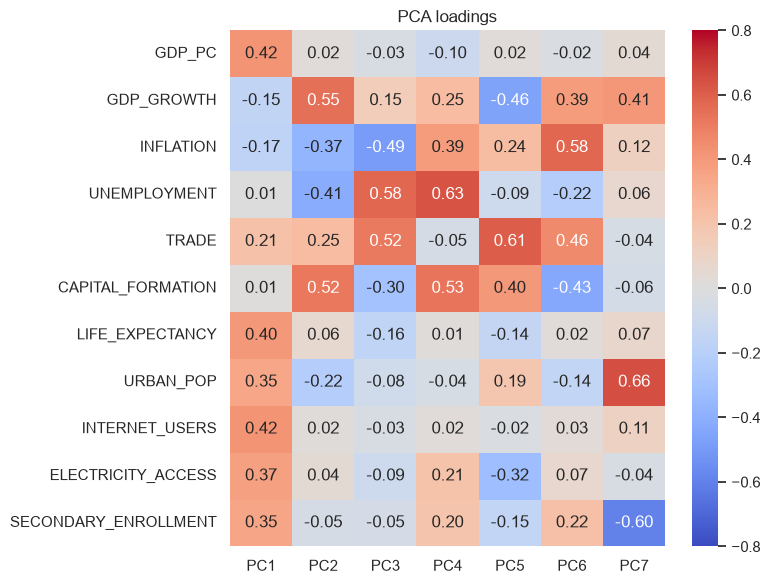

In [11]:
loadings = pd.DataFrame(pca.components_[:7].T, index=names, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7'])
if loadings.loc['GDP_PC', 'PC1'] < 0:
    loadings['PC1'] = -loadings['PC1']
if loadings.loc['GDP_GROWTH', 'PC2'] < 0:
    loadings['PC2'] = -loadings['PC2']
if loadings.loc['UNEMPLOYMENT', 'PC3'] < 0:
    loadings['PC3'] = -loadings['PC3']
plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.8, vmax=0.8)
plt.title('PCA loadings')
plt.tight_layout()
plt.savefig('../figures/03_loadings.png', dpi=200)
plt.show()

In [12]:
for pc in ['PC1', 'PC2', 'PC3']:
    print(pc)
    print(loadings[pc].sort_values().round(2))

PC1
INFLATION              -0.17
GDP_GROWTH             -0.15
UNEMPLOYMENT            0.01
CAPITAL_FORMATION       0.01
TRADE                   0.21
URBAN_POP               0.35
SECONDARY_ENROLLMENT    0.35
ELECTRICITY_ACCESS      0.37
LIFE_EXPECTANCY         0.40
GDP_PC                  0.42
INTERNET_USERS          0.42
Name: PC1, dtype: float64
PC2
UNEMPLOYMENT           -0.41
INFLATION              -0.37
URBAN_POP              -0.22
SECONDARY_ENROLLMENT   -0.05
INTERNET_USERS          0.02
GDP_PC                  0.02
ELECTRICITY_ACCESS      0.04
LIFE_EXPECTANCY         0.06
TRADE                   0.25
CAPITAL_FORMATION       0.52
GDP_GROWTH              0.55
Name: PC2, dtype: float64
PC3
INFLATION              -0.49
CAPITAL_FORMATION      -0.30
LIFE_EXPECTANCY        -0.16
ELECTRICITY_ACCESS     -0.09
URBAN_POP              -0.08
SECONDARY_ENROLLMENT   -0.05
GDP_PC                 -0.03
INTERNET_USERS         -0.03
GDP_GROWTH              0.15
TRADE                   0.52
UNEMPLOY

### Countries on PC1 and PC2

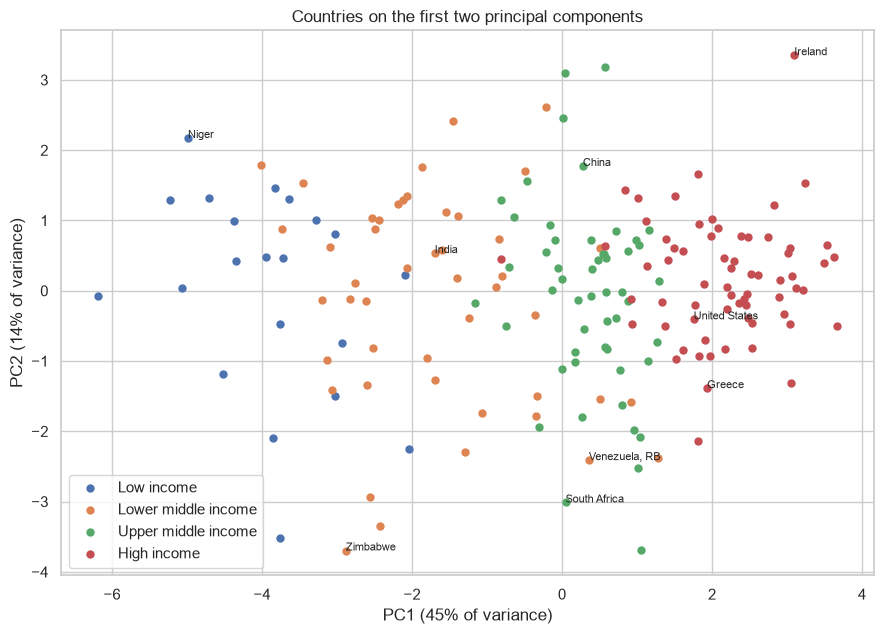

In [13]:
scores = pca.transform(Z)
df['PC1'] = scores[:, 0]
df['PC2'] = scores[:, 1]
if pca.components_[0][0] < 0:
    df['PC1'] = -df['PC1']
if pca.components_[1][1] < 0:
    df['PC2'] = -df['PC2']

plt.figure(figsize=(9, 6.5))
for group in income_order:
    part = df[df['income_group'] == group]
    plt.scatter(part['PC1'], part['PC2'], s=25, label=group)
for country in ['India', 'China', 'Ireland', 'South Africa', 'Zimbabwe', 'Greece', 'United States', 'Niger', 'Venezuela, RB']:
    row = df[df['country'] == country]
    plt.annotate(country, (row['PC1'].values[0], row['PC2'].values[0]), fontsize=8)
plt.xlabel(f'PC1 ({evr[0] * 100:.0f}% of variance)')
plt.ylabel(f'PC2 ({evr[1] * 100:.0f}% of variance)')
plt.title('Countries on the first two principal components')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/03_pca_scatter.png', dpi=200)
plt.show()